<!-- Generated by scripts/reference.ts from the doc comments in runtime/display.d.mts, runtime/sql.d.mts, runtime/host.d.mts, src/globals.ts. Edit those, then run `node scripts/reference.ts --write`. -->

# `jupyter` reference

Every member of the `jupyter` global and the `prompt` and `confirm`
globals, with their arguments, return values and an example. Examples
that can run on their own show the output they produced. [The
`jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api) explains the members with longer
examples. Widgets and comms are in the [widgets
reference](https://cdp-kernel.org/docs/widgets-reference).


**Showing output**

| Member | What it does |
| --- | --- |
| [`jupyter.display(obj, options?)`](#jupyter-display-obj-options) | Show a value now, in the middle of a cell, or replace one shown earlier. |
| [`` jupyter.md`…` ``](#jupyter-md) | A tagged template that renders as Markdown. |
| [`` jupyter.html`…` ``](#jupyter-html) | A tagged template that renders as HTML. |
| [`` jupyter.svg`…` ``](#jupyter-svg) | A tagged template that renders as SVG. |
| [`jupyter.image(obj)`](#jupyter-image-obj) | Show a PNG or JPEG. |
| [`jupyter.$display`](#jupyter-display) | The symbol a class implements to choose how its instances appear. |
| [`jupyter.format(obj)`](#jupyter-format-obj) | The MIME bundle that displaying a value would send, without showing anything. |
| [`jupyter.broadcast(msgType, content, options?)`](#jupyter-broadcast-msgtype-content-options) | Send a raw Jupyter message on the kernel's output channel (IOPub), as a reply to the running cell. |

**Data**

| Member | What it does |
| --- | --- |
| [`jupyter.table(value, options?)`](#jupyter-table-value-options) | Show rows and columns as a table. |
| [`jupyter.sql`](#jupyter-sql) | Run SQL on an in-memory [DuckDB](https://duckdb.org) database, as a tagged template: each `${value}` becomes a bound parameter, never query text, so values can't change the query. |
| [`jupyter.sql.query(text, params?)`](#jupyter-sql-query-text-params) | Run SQL from a string, with values for its `?` parameters. |
| [`jupyter.sql.raw(text)`](#jupyter-sql-raw-text) | Text the tag puts into the query as written, rather than as a parameter: a table name or a file path built in code. |
| [`jupyter.sql.load(name, source)`](#jupyter-sql-load-name-source) | Create (or replace) table `name` from a file DuckDB can read (CSV, Parquet or JSON, by path or URL), from an array of row objects, or from an Arrow table or Polars DataFrame. |
| [`jupyter.sql.close()`](#jupyter-sql-close) | Close the database and free its memory. |
| [`jupyter.sql.connection()`](#jupyter-sql-connection) | The DuckDB connection itself, for what the tag doesn't cover: a `@duckdb/node-api` `DuckDBConnection` on Node, Deno and Bun, a duckdb-wasm `AsyncDuckDBConnection` in the browser. |
| [`jupyter.chart(chart, options?)`](#jupyter-chart-chart-options) | Draw a chart in the kernel as one SVG, with its title and legend inside, plus a text summary for readers that can't see it. |

**Asking and interrupting**

| Member | What it does |
| --- | --- |
| [`prompt(message?, defaultValue?, options?)`](#prompt-message-defaultvalue-options) | Ask for a line of input in the notebook: the frontend shows an input box under the cell, and the cell waits for the answer. |
| [`confirm(message?)`](#confirm-message) | Ask a yes/no question in the notebook. |
| [`jupyter.signal`](#jupyter-signal) | An `AbortSignal` that an interrupt aborts, so code waiting on something only it can end can stop and clean up. |
| [`jupyter.comm`](#jupyter-comm) | Jupyter comms: message channels to the frontend outside cell execution. |
| [`jupyter.widget(options)`](#jupyter-widget-options) | Create an [anywidget](https://anywidget.dev)-compatible [widget model](https://cdp-kernel.org/docs/widgets-reference#widget-model). |

**Notebooks as programs**

| Member | What it does |
| --- | --- |
| [`jupyter.params`](#jupyter-params) | The parameters of this run: a frozen object, empty unless whoever started the kernel passed some, such as `ganymede execute -p counter="2nd Ave"`. |
| [`jupyter.result(name, value)`](#jupyter-result-name-value) | Publish a value under a name, as an output that a run's caller reads by name instead of parsing outputs: `ganymede execute --results`, or another notebook. |
| [`jupyter.host(options?)`](#jupyter-host-options) | The Ganymede server running this kernel, through its host API: read, search and (when granted) run other notebooks under its root. |
| [`host.has(method)`](#host-has-method) | Whether this notebook may call `method`. |
| [`host.call(method, params?, options?)`](#host-call-method-params-options) | Call a method by name. |
| [`host.notebooks.list(params?, options?)`](#host-notebooks-list-params-options) | The notebooks this notebook may read, and the folders, in a folder. |
| [`host.notebooks.read(params, options?)`](#host-notebooks-read-params-options) | A notebook as nbformat JSON (from its open document when someone has it open), and each cell's source hash by cell id. |
| [`host.notebooks.search(params, options?)`](#host-notebooks-search-params-options) | Cells that hold every word of `query`, in the notebooks this notebook may read: in sources, and in outputs too with `outputs: true`. |
| [`host.notebooks.results(params, options?)`](#host-notebooks-results-params-options) | A notebook's named results. |
| [`host.notebooks.run(params, options?)`](#host-notebooks-run-params-options) | Run a notebook with parameters and return its results, in a fresh kernel, when this notebook's grant names it. |
| [`host.self.add(params?, options?)`](#host-self-add-params-options) | Add a cell to this notebook. |
| [`host.self.edit(params?, options?)`](#host-self-edit-params-options) | Change a cell's source, given the hash of the source it replaces. |
| [`host.self.delete(params?, options?)`](#host-self-delete-params-options) | Delete a cell, given its source's hash. |

## `jupyter`

The `jupyter` global: how values appear in the notebook. The same object
as `Deno.jupyter` in `deno jupyter`.

### `jupyter.display(obj, options?)`

```ts
display(obj: unknown, options?: DisplayOptions): Promise<void>;
```

Show a value now, in the middle of a cell, or replace one shown
earlier. The value can be anything a cell could end with: a template
from `md`, `html` or `svg`, an image, a widget, an object with a
`[jupyter.$display]` method, or a plain value, shown as text.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `obj` | `unknown` | yes | The value to show. |
| `options` | `DisplayOptions` | no | `display_id` and `update` to replace an earlier output; `raw` to send a plain object as the MIME bundle itself. |

**Returns** `Promise<void>`: Resolves once the output is sent. Without `await` the output still appears, but later output in the cell can appear before it.

In [1]:
const bar = (pct: number) => jupyter.html`<progress value="${pct}" max="100"></progress>`;
await jupyter.display(bar(0), { display_id: "download" });
for (let pct = 25; pct <= 100; pct += 25) {
  await new Promise((resolve) => setTimeout(resolve, 500));
  await jupyter.display(bar(pct), { display_id: "download", update: true });
}

In [2]:
// A MIME bundle sent as is: JupyterLab renders it as a JSON tree.
const user = { name: "Ada", active: true };
await jupyter.display(
  { "application/json": user, "text/plain": JSON.stringify(user) },
  { raw: true },
);

{"name":"Ada","active":true}

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#showing-output-with-display)

### `` jupyter.md`…` ``

```ts
md(strings: TemplateStringsArray, ...values: unknown[]): Displayable;
```

A tagged template that renders as Markdown. Interpolated values are
inserted as is, without escaping.

**Returns** `Displayable`: A value that shows as `text/markdown` as a cell's result or through `display`.

In [3]:
const scores = { Ada: 92, Grace: 88 };
const rows = Object.entries(scores).map(([n, s]) => `| ${n} | ${s} |`).join("\n");
jupyter.md`| Name | Score |
| --- | --- |
${rows}`;

| Name | Score |
| --- | --- |
| Ada | 92 |
| Grace | 88 |

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#markdown)

### `` jupyter.html`…` ``

```ts
html(strings: TemplateStringsArray, ...values: unknown[]): Displayable;
```

A tagged template that renders as HTML. Interpolated values are
inserted as is, without escaping: escape text from users, files or
the network yourself.

**Returns** `Displayable`: A value that shows as `text/html`.

In [4]:
const escape = (s: string) => s.replace(/[&<>"']/g, (c) => `&#${c.charCodeAt(0)};`);
const comment = "<script>alert(1)</script>";
jupyter.html`<p>${escape(comment)}</p>`;

<script>alert(1)</script>

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#html)

### `` jupyter.svg`…` ``

```ts
svg(strings: TemplateStringsArray, ...values: unknown[]): Displayable;
```

A tagged template that renders as SVG. Include the `xmlns` attribute.
Interpolated values are inserted as is, without escaping.

**Returns** `Displayable`: A value that shows as `image/svg+xml`.

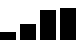

In [5]:
const data = [4, 8, 15, 16];
const bars = data.map((v, i) => `<rect x="${i * 20}" y="${40 - v * 2}" width="16" height="${v * 2}"/>`).join("");
jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="80" height="40">${bars}</svg>`;

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#svg)

### `jupyter.image(obj)`

```ts
image(obj: string | Uint8Array): Displayable;
```

Show a PNG or JPEG. The format is read from the bytes, not the file
name.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `obj` | `string \| Uint8Array` | yes | A file path, relative to the notebook's directory, or the image's bytes. |

**Returns** `Displayable`: A value that shows as `image/png` or `image/jpeg`.

**Throws** `TypeError`: The bytes are not PNG or JPEG, or the path can't be read.

**Availability**: Paths need a file system: on workerd and celld pass bytes.

```ts
jupyter.image("./chart.png");
```

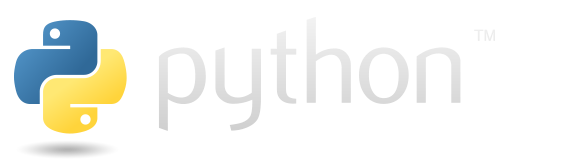

In [6]:
const response = await fetch("https://www.python.org/static/img/python-logo.png");
jupyter.image(new Uint8Array(await response.arrayBuffer()));

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#images)

### `jupyter.$display`

```ts
$display: typeof $display;
```

The symbol a class implements to choose how its instances appear. The
method returns a MIME bundle, or a promise of one. It is used for a
cell's result, `display` and `format`, but not for objects nested in
other values. At runtime it is `Symbol.for("Jupyter.display")`.

In [7]:
class Temperature {
  celsius: number;
  constructor(celsius: number) {
    this.celsius = celsius;
  }
  [jupyter.$display]() {
    return { "text/plain": `${this.celsius}°C`, "text/html": `<b>${this.celsius}°C</b>` };
  }
}
new Temperature(21);

21°C

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#custom-display-for-your-own-classes)

### `jupyter.format(obj)`

```ts
format(obj: unknown): Promise<MediaBundle>;
```

The MIME bundle that displaying a value would send, without showing
anything. For plain values `text/plain` holds terminal color codes,
as the notebook shows them.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `obj` | `unknown` | yes | The value to format. |

**Returns** `Promise<MediaBundle>`: The bundle, for example `{ "text/plain": "\x1b[33m42\x1b[39m" }` for `42`.

In [8]:
const bundle = await jupyter.format(jupyter.md`# Weekly report`);
bundle["text/markdown"]; // "# Weekly report"

'# Weekly report'

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#getting-a-bundle-with-format)

### `jupyter.broadcast(msgType, content, options?)`

```ts
broadcast(
  msgType: string,
  content: object,
  options?: { metadata?: object; buffers?: Uint8Array[] },
): void;
```

Send a raw Jupyter message on the kernel's output channel (IOPub), as a
reply to the running cell. The other helpers are built on it. It does
not check the message: a wrong field is ignored or mishandled by the
frontend.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `msgType` | `string` | yes | An IOPub message type, such as `"clear_output"` or `"display_data"`. |
| `content` | `object` | yes | The message content, as the messaging spec defines it for `msgType`. |
| `options` | `{ metadata?: object; buffers?: Uint8Array[] }` | no | `metadata` for the message, and binary `buffers`. |

In [9]:
// Count down in place: clear_output with wait avoids a flicker.
for (const n of [3, 2, 1]) {
  jupyter.broadcast("clear_output", { wait: true });
  await jupyter.display(jupyter.md`Launching in **${n}**…`);
  await new Promise((resolve) => setTimeout(resolve, 1000));
}

Launching in **1**…

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#raw-messages-with-broadcast)

### `jupyter.table(value, options?)`

```ts
table(value: unknown, options?: TableOptions): Displayable;
```

Show rows and columns as a table. The output has Ganymede's table
type, `application/vnd.dataresource+json` (Table Schema fields, up to
`limit` rows as JSON, and the total row count), which the Ganymede
apps show with sorting and paging; a plain HTML table of the first
and last rows for JupyterLab and VS Code; and a text summary of each
column's type and range for agents and consoles.

An Arrow table, a Polars DataFrame or a DuckDB result also shows this
way when it is a cell's value; pass one here to set `limit`,
`columns` or `title`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `value` | `unknown` | yes | An array of row objects, an array of arrays (name them with `columns`), an Arrow table (apache-arrow, duckdb-wasm), a Polars DataFrame, or a `@duckdb/node-api` result. |
| `options` | `TableOptions` | no | `limit`: rows to embed, default 1,000, at most 10,000, and never more than 1 MB of JSON. `columns`: which columns, in order. `title`: a caption. |

**Returns** `Displayable`

**Throws** `TypeError`: `value` isn't one of those, or `limit` isn't a whole number.

In [10]:
const moons = [
  { moon: "Io", radius_km: 1821.6, discovered: new Date("1610-01-08") },
  { moon: "Europa", radius_km: 1560.8, discovered: new Date("1610-01-08") },
  { moon: "Ganymede", radius_km: 2634.1, discovered: new Date("1610-01-07") },
];
jupyter.table(moons, { title: "Galilean moons" });

moonstring,radius_kmnumber,discovereddate
Io,1821.6,1610-01-08
Europa,1560.8,1610-01-08
Ganymede,2634.1,1610-01-07


Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#tables)

### `jupyter.sql`

```ts
readonly sql: Sql;
```

Run SQL on an in-memory [DuckDB](https://duckdb.org) database, as a
tagged template: each `${value}` becomes a bound parameter, never
query text, so values can't change the query. Resolves to a
`SqlResult`, which shows as a table and has `columns` and `rows`.

The database opens on the first query and lasts until the kernel
restarts or `jupyter.sql.close()`. DuckDB reads CSV, Parquet and JSON
files by path or URL; `jupyter.sql.load` makes a table from rows the
notebook already has. An interrupt stops a running query.

**Throws** `TypeError`: Called as a function rather than a tag.

**Availability**: Node, Deno and Bun use `@duckdb/node-api`; the browser target (the Ganymede apps) uses duckdb-wasm from a CDN. Not on workerd or celld.

In [11]:
const min = 2000;
await jupyter.sql`
  select moon, radius_km
  from (values ('Io', 1821.6), ('Ganymede', 2634.1), ('Callisto', 2410.3)) as m(moon, radius_km)
  where radius_km > ${min}
  order by radius_km desc`;

moonstring,radius_kmnumber
Ganymede,2634.1
Callisto,2410.3


Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#sql-with-duckdb)

### `jupyter.chart(chart, options?)`

```ts
chart(chart: object, options?: ChartOptions | Record<string, unknown>): Displayable;
```

Draw a chart in the kernel as one SVG, with its title and legend
inside, plus a text summary for readers that can't see it. The SVG
shows the same in the Ganymede apps, JupyterLab, VS Code and a
published page. Text and axes are drawn in `currentColor`: the
notebook's text color in the Ganymede apps, black in JupyterLab.

Pass a [Vega-Lite](https://vega.github.io/vega-lite/) or Vega spec
(or a vega-lite-api chart), or the
[Observable Plot](https://observablehq.com/plot/) module and the
options you would give `Plot.plot`. Plot's `title`, `subtitle`,
`caption` and the color legend (`legend: true`, `"swatches"` or
`"ramp"`) are drawn into the SVG; other scales' legends are left
out. An SVG element shows as it is.

vega and vega-lite (version 6), and linkedom for Plot where there is
no DOM, load through the cell's import on first use. A chart past
2 MB of SVG logs a warning: aggregate or sample first.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `chart` | `object` | yes | A Vega-Lite or Vega spec, the Plot module, or an SVG element. |
| `options` | `ChartOptions \| Record<string, unknown>` | no | With a spec, `ChartOptions`; with Plot, Plot's options. |

**Returns** `Displayable`

**Throws** `TypeError`: `chart` is none of those, or Plot comes without options.

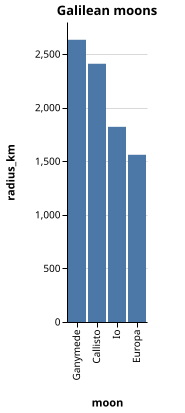

In [12]:
jupyter.chart({
  title: "Galilean moons",
  data: { values: [
    { moon: "Io", radius_km: 1821.6 },
    { moon: "Europa", radius_km: 1560.8 },
    { moon: "Ganymede", radius_km: 2634.1 },
    { moon: "Callisto", radius_km: 2410.3 },
  ] },
  mark: "bar",
  encoding: {
    x: { field: "moon", sort: "-y" },
    y: { field: "radius_km", type: "quantitative" },
  },
});

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#charts)

### `jupyter.signal`

```ts
readonly signal: AbortSignal;
```

An `AbortSignal` that an interrupt aborts, so code waiting on something
only it can end can stop and clean up. Each cell gets its own, as does
a comm handler that starts while no cell runs. Read it once when the
work starts: a later read gets the signal of whatever started last.
The abort reason is a `DOMException` named `AbortError`.

```ts
const response = await fetch("https://example.com/large.csv", { signal: jupyter.signal });
```

```ts
const signal = jupyter.signal;
const ask = jupyter.comm.open("my.app", { question: "ready?" });
const answer = await new Promise((resolve, reject) => {
  ask.onMsg((m) => resolve(m.data));
  signal.addEventListener("abort", () => { ask.close(); reject(signal.reason); }, { once: true });
});
```

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#stopping-on-interrupt-jupyter-signal)

### `jupyter.comm`

```ts
comm: CommApi;
```

Jupyter comms: message channels to the frontend outside cell
execution. Its methods are in the widgets and comms reference.

Guide: [Widgets and comms](https://cdp-kernel.org/docs/widgets#comms)

### `jupyter.widget(options)`

```ts
widget(options: WidgetOptions): Widget;
```

Create an [anywidget](https://anywidget.dev)-compatible [widget
model](https://cdp-kernel.org/docs/widgets-reference#widget-model). Display it (or end the
cell with it) to show a view.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `options` | `WidgetOptions` | yes | The view module, its CSS, and the initial state. |

**Returns** `Widget`: The model, synced with every view of it.

**Throws** `TypeError`: `options.esm` is not a string.

**Availability**: The frontend needs the [anywidget](https://anywidget.dev) extension.

In [13]:
const counter = jupyter.widget({
  esm: `export default {
    render({ model, el }) {
      const button = document.createElement("button");
      const update = () => {
        button.textContent = "count is " + model.get("count");
      };
      button.onclick = () => {
        model.set("count", model.get("count") + 1);
        model.save_changes();
      };
      model.on("change:count", update);
      update();
      el.append(button);
    },
  };`,
  state: { count: 0 },
});
counter; // the cell's result: displays the widget

Widget(widget-1)

Guide: [Widgets and comms](https://cdp-kernel.org/docs/widgets#a-first-widget-a-counter)

### `jupyter.params`

```ts
readonly params: { readonly [name: string]: JsonValue };
```

The parameters of this run: a frozen object, empty unless whoever
started the kernel passed some, such as `ganymede execute -p
counter="2nd Ave"`. They arrive as a JSON object in the kernel's
`GANYMEDE_PARAMS` environment variable. Take defaults with
destructuring, so the notebook also runs on its own.

**Throws** `TypeError`: `GANYMEDE_PARAMS` is set but isn't a JSON object.

**Availability**: Node, Deno, Bun, workerd and celld read the kernel's environment; the browser target takes `params` from its options.

In [14]:
const { counter = "Fremont", days = 30 } = jupyter.params as { counter?: string; days?: number };
`${counter}, last ${days} days`;

'Fremont, last 30 days'

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#parameters-and-named-results)

### `jupyter.result(name, value)`

```ts
result(name: string, value: unknown): void;
```

Publish a value under a name, as an output that a run's caller reads
by name instead of parsing outputs: `ganymede execute --results`, or
another notebook. The output has the MIME type
`application/vnd.ganymede.result+json` holding `{ name, value }`, and
a `text/plain` line `name = value` for frontends that don't know the
type. When a name is published twice, readers take the last one.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `name` | `string` | yes | The result's name. |
| `value` | `unknown` | yes | Any value `JSON.stringify` accepts; it is stored as JSON, so a `Date` becomes its ISO string. |

**Throws** `TypeError`: `name` is empty, or `value` isn't JSON (a function, `undefined`, a `BigInt` or a cycle).

In [15]:
const counts = [3120, 2890, 2410];
jupyter.result("weekday_drop", (counts[2] - counts[0]) / counts[0]);
jupyter.result("counts", counts);

weekday_drop = -0.22756410256410256

counts = [3120,2890,2410]

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#parameters-and-named-results)

### `jupyter.host(options?)`

```ts
host(options?: HostOptions): Promise<Host | null>;
```

The Ganymede server running this kernel, through its host API: read,
search and (when granted) run other notebooks under its root. The
server opens a comm to the kernel when it starts; this resolves to
`null` when none answers, as under plain Jupyter.

Each call returns a promise and takes `{ signal }`, by default
`jupyter.signal`, so an interrupt cancels it. A failed call rejects
with a `HostError` whose `code` says why: `denied` for a notebook or
method this notebook isn't granted. Branch on `code`: `HostError`
isn't a global, so `instanceof` isn't available.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `options` | `HostOptions` | no | `timeout`: how long to wait for a server, in ms. |

**Returns** `Promise<Host | null>`

**Throws** `HostError`: `cancelled` when an interrupt ends the wait.

```ts
const host = await jupyter.host();
if (host) {
  const { hits } = await host.notebooks.search({ query: "weekday drop", dir: "journal" });
  hits.map((h) => `${h.path}: ${h.excerpt}`);
}
```

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#other-notebooks-jupyter-host)

## `Sql`

`jupyter.sql`: a tagged template that runs SQL on the kernel's DuckDB.
Each `${value}` becomes a bound parameter.

Methods of [`jupyter.sql`](#jupyter-sql), beside the tag itself.

### `jupyter.sql.query(text, params?)`

```ts
query(text: string, params?: unknown[]): Promise<SqlResult>;
```

Run SQL from a string, with values for its `?` parameters. For a
query built at run time; prefer the tag otherwise.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `text` | `string` | yes | The SQL. |
| `params` | `unknown[]` | no | Values for its `?` placeholders, in order. |

**Returns** `Promise<SqlResult>`

In [16]:
const op = ">";
await jupyter.sql.query(`select 2 ${op} ? as answer`, [1]);

answerboolean
true


### `jupyter.sql.raw(text)`

```ts
raw(text: string): SqlFragment;
```

Text the tag puts into the query as written, rather than as a
parameter: a table name or a file path built in code. Never pass it
text from outside the notebook.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `text` | `string` | yes | SQL text. |

**Returns** `SqlFragment`

```ts
const table = "moons";
await jupyter.sql`select count(*) as n from ${jupyter.sql.raw(table)}`;
```

### `jupyter.sql.load(name, source)`

```ts
load(name: string, source: unknown): Promise<void>;
```

Create (or replace) table `name` from a file DuckDB can read (CSV,
Parquet or JSON, by path or URL), from an array of row objects, or
from an Arrow table or Polars DataFrame. Rows go in as one JSON
parameter, typed from the values: integers as `BIGINT`, numbers as
`DOUBLE`, `Date`s as `TIMESTAMP`, arrays and objects as `JSON`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `name` | `string` | yes | The table's name. |
| `source` | `unknown` | yes | A path or URL, rows, an Arrow table or a DataFrame. |

**Returns** `Promise<void>`

**Throws** `TypeError`: `name` is empty, or the rows have no columns.

In [17]:
await jupyter.sql.load("moons", [
  { moon: "Io", radius_km: 1821.6 },
  { moon: "Ganymede", radius_km: 2634.1 },
]);
await jupyter.sql`select moon from moons order by radius_km desc`;

moonstring
Ganymede
Io


### `jupyter.sql.close()`

```ts
close(): Promise<void>;
```

Close the database and free its memory. The next query opens a new,
empty one.

**Returns** `Promise<void>`

```ts
await jupyter.sql.close();
```

### `jupyter.sql.connection()`

```ts
connection(): Promise<unknown>;
```

The DuckDB connection itself, for what the tag doesn't cover: a
`@duckdb/node-api` `DuckDBConnection` on Node, Deno and Bun, a
duckdb-wasm `AsyncDuckDBConnection` in the browser.

**Returns** `Promise<unknown>`

```ts
const conn = await jupyter.sql.connection();
```

## `Host`

The Ganymede server that runs this kernel, from `jupyter.host()`.

`await jupyter.host()` returns it; see [`jupyter.host`](#jupyter-host-options).

### `host.has(method)`

```ts
has(method: string): boolean;
```

Whether this notebook may call `method`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `method` | `string` | yes | The method, such as `"notebooks.run"`. |

**Returns** `boolean`

```ts
const host = await jupyter.host();
host?.has("notebooks.run"); // false unless the notebook is granted runs
```

### `host.call(method, params?, options?)`

```ts
call(method: string, params?: HostParams, options?: HostCallOptions): Promise<any>;
```

Call a method by name. The shortcuts under `notebooks` and `self` call
this.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `method` | `string` | yes | The method, such as `"notebooks.read"`. |
| `params` | `HostParams` | no | Its parameters, a JSON object. Default `{}`. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<any>`: What the server answered, as JSON.

**Throws** `HostError`: The call failed; `code` says why.

```ts
const host = await jupyter.host();
const { notebook } = await host!.call("notebooks.read", { path: "journal/a.ipynb" });
notebook.cells.length;
```

### Properties

| Property | Type | Description |
| --- | --- | --- |
| `protocol` | `number` | The host API's protocol version. |
| `server` | `string` | The server's version. |
| `notebook` | `string \| null` | This notebook's path under the server's root, or null when the kernel has none. |
| `methods` | `readonly string[]` | The methods this notebook may call. |
| `notebooks` | `HostNotebooks` | Other notebooks under the server's root, as far as this notebook's grant reaches. |
| `self` | `HostSelf` | This notebook's own cells. Ganymede 0.8.0 or later; an older server rejects `unavailable`. |

## `host.notebooks`

`host.notebooks`: other notebooks under the server's root.

### `host.notebooks.list(params?, options?)`

```ts
list(params?: { dir?: string }, options?: HostCallOptions): Promise<NotebookEntry[]>;
```

The notebooks this notebook may read, and the folders, in a folder.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `{ dir?: string }` | no | `dir`: the folder, relative to the root. Default the root. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<NotebookEntry[]>`: One entry per notebook or folder.

**Throws** `HostError`: `denied` when the grant doesn't reach `dir`.

```ts
const host = await jupyter.host();
const entries = await host!.notebooks.list({ dir: "journal" });
entries.filter((e) => e.type === "notebook").map((e) => e.title ?? e.path);
```

### `host.notebooks.read(params, options?)`

```ts
read(params: { path: string }, options?: HostCallOptions): Promise<{ notebook: any; hashes: { [cellId: string]: string } }>;
```

A notebook as nbformat JSON (from its open document when someone has
it open), and each cell's source hash by cell id.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `{ path: string }` | yes | `path`: the notebook, relative to the root. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<{ notebook: any; hashes: { [cellId: string]: string } }>`: The notebook and its hashes.

**Throws** `HostError`: `denied` when the grant doesn't reach `path`.

```ts
const host = await jupyter.host();
const { notebook } = await host!.notebooks.read({ path: "journal/a.ipynb" });
notebook.cells.length;
```

### `host.notebooks.search(params, options?)`

```ts
search(
  params: { query: string; dir?: string; outputs?: boolean; cell_type?: "code" | "markdown" | "raw"; limit?: number },
  options?: HostCallOptions,
): Promise<NotebookSearch>;
```

Cells that hold every word of `query`, in the notebooks this notebook
may read: in sources, and in outputs too with `outputs: true`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `{ query: string; dir?: string; outputs?: boolean; cell_type?: "code" \| "markdown" \| "raw"; limit?: number }` | yes | `query`, and optionally `dir`, `outputs`, `cell_type` (`code`, `markdown` or `raw`) and `limit` (default 20, at most 200). |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<NotebookSearch>`: The matches, how many there are in all, and whether `limit` cut them.

```ts
const host = await jupyter.host();
const { hits } = await host!.notebooks.search({ query: "weekday drop", dir: "journal" });
hits.map((h) => `${h.path}: ${h.excerpt}`);
```

### `host.notebooks.results(params, options?)`

```ts
results(params: { path: string }, options?: HostCallOptions): Promise<any>;
```

A notebook's named results. Ganymede 0.8.0 or later; an older server
rejects `unavailable`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `{ path: string }` | yes | `path`: the notebook. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<any>`

```ts
const host = await jupyter.host();
const results = await host!.notebooks.results({ path: "journal/fremont.ipynb" });
```

### `host.notebooks.run(params, options?)`

```ts
run(params: { path: string; params?: HostParams }, options?: HostCallOptions): Promise<any>;
```

Run a notebook with parameters and return its results, in a fresh
kernel, when this notebook's grant names it. Ganymede 0.8.0 or later;
an older server rejects `unavailable`.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `{ path: string; params?: HostParams }` | yes | `path`: the notebook; `params`: its parameters. |
| `options` | `HostCallOptions` | no | `signal` cancels the run. |

**Returns** `Promise<any>`

```ts
const host = await jupyter.host();
const run = await host!.notebooks.run({ path: "journal/fremont.ipynb", params: { counter: "2nd Ave" } });
```

## `host.self`

`host.self`: this notebook's own cells. Ganymede 0.8.0 or later; an older server rejects each with `unavailable`.

### `host.self.add(params?, options?)`

```ts
add(params?: HostParams, options?: HostCallOptions): Promise<any>;
```

Add a cell to this notebook.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `HostParams` | no | The cell, as the host API's design note describes. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<any>`

```ts
const host = await jupyter.host();
await host!.self.add({ cell_type: "markdown", source: "## Index" });
```

### `host.self.edit(params?, options?)`

```ts
edit(params?: HostParams, options?: HostCallOptions): Promise<any>;
```

Change a cell's source, given the hash of the source it replaces.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `HostParams` | no | The cell id, its new source and the old source's hash. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<any>`

```ts
const host = await jupyter.host();
const { notebook, hashes } = await host!.notebooks.read({ path: host!.notebook! });
const id = notebook.cells[0].id;
await host!.self.edit({ id, source: "# New title", source_hash: hashes[id] });
```

### `host.self.delete(params?, options?)`

```ts
delete(params?: HostParams, options?: HostCallOptions): Promise<any>;
```

Delete a cell, given its source's hash.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `params` | `HostParams` | no | The cell id and its source's hash. |
| `options` | `HostCallOptions` | no | `signal` cancels the call. |

**Returns** `Promise<any>`

```ts
const host = await jupyter.host();
const { notebook, hashes } = await host!.notebooks.read({ path: host!.notebook! });
const id = notebook.cells.at(-1).id;
await host!.self.delete({ id, source_hash: hashes[id] });
```

## Globals

### `prompt(message?, defaultValue?, options?)`

```ts
function prompt(message?: string, defaultValue?: string, options?: PromptOptions): string | null;
```

Ask for a line of input in the notebook: the frontend shows an input
box under the cell, and the cell waits for the answer.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `message` | `string` | no | The question. Default `"Prompt"`. A non-empty `defaultValue` is shown after it, as `message [default]`. |
| `defaultValue` | `string` | no | Returned when the answer is empty. Default `""`. |
| `options` | `PromptOptions` | no | `password: true` hides what is typed. |

**Returns** `string | null`: The typed text, `defaultValue` for an empty answer, or `null` when nothing can answer (the frontend allows no input, as in `nbconvert --execute`).

**Availability**: On workerd and celld it always returns `null`.

```ts
const name = prompt("What's your name?", "world");
`Hello, ${name}!`;
```

```ts
const apiKey = prompt("API key", "", { password: true });
```

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#asking-for-input-prompt-and-confirm)

### `confirm(message?)`

```ts
function confirm(message?: string): boolean;
```

Ask a yes/no question in the notebook. `[y/N]` is added to the message.

| Parameter | Type | Required | Description |
| --- | --- | --- | --- |
| `message` | `string` | no | The question. Default `"Confirm"`. |

**Returns** `boolean`: `true` only for `y` or `Y`; `false` otherwise, and when nothing can answer.

**Availability**: On workerd and celld it always returns `false`.

```ts
if (confirm("Delete the cache?")) console.log("deleting");
```

Guide: [The `jupyter` namespace](https://cdp-kernel.org/docs/jupyter-api#asking-for-input-prompt-and-confirm)

## Types

### `DisplayOptions`

Options for `jupyter.display`.

| Property | Type | Required | Description |
| --- | --- | --- | --- |
| `raw` | `boolean` | no | Send a plain object as the MIME bundle itself instead of formatting it. Default `false`. |
| `update` | `boolean` | no | Replace every earlier output that has the same `display_id`, including one shown by an earlier cell, instead of adding an output. Needs `display_id`. Default `false`. |
| `display_id` | `string` | no | An id that a later display with `update: true` can replace. |

### `HostOptions`

Options for `jupyter.host()`.

| Property | Type | Required | Description |
| --- | --- | --- | --- |
| `timeout` | `number` | no | How long to wait for a server that hasn't opened the comm, in ms. Default 1000. Once a wait goes unanswered, later calls answer `null` at once. |

### `HostCallOptions`

Options for a host call.

| Property | Type | Required | Description |
| --- | --- | --- | --- |
| `signal` | `AbortSignal` | no | Aborting it cancels the call. Default `jupyter.signal`. |

### `PromptOptions`

Options for the notebook's `prompt()`.

| Property | Type | Required | Description |
| --- | --- | --- | --- |
| `password` | `boolean` | no | Ask the frontend to hide what is typed, for secrets. Default `false`. |

### `MediaBundle`

A Jupyter MIME bundle: media type to content, such as
`{ "text/plain": "42", "text/html": "<b>42</b>" }`. Binary images are
base64 strings; JSON types (`application/json`, Vega-Lite) are objects.

```ts
export type MediaBundle = { [mediaType: string]: unknown };
```

### `Displayable`

A value that renders as rich output: it has a `[jupyter.$display]` method.

| Property | Type | Required | Description |
| --- | --- | --- | --- |
| `[jupyter.$display]` | `() => MediaBundle \| Promise<MediaBundle>` | yes | Returns the value's MIME bundle, or a promise of one. |